# Model Evaluation

Comparison of the best hyperparameterization of each benchmarked model over the 360 PSPLIB projects.

**Benchmarked models (regression problem)**

- Explainable Boosting Machine (`ebm`)
- Random Forest (`rf`)
- XGBoost (`xgb`)
- Support Vector Regression (`sv`)
- Elastic Net (`en`)
- FastAI tabular neural network (`fastai`)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss
import scikit_posthocs as sp

In [2]:
sns.set_theme(style="darkgrid")
sns.set_palette("tab10")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 6)

## Analysis of the model evaluation

The model-selection notebook identified one best LHS configuration per model. Here those six selected models are evaluated on the full set of 360 projects.

For each comparison, projects are treated as blocks and models as repeated treatments. Lower `RelMSE` is better. We apply a Friedman test to evaluate whether all models have equal performance and, when the null hypothesis is rejected, a Conover post-hoc test with Bonferroni correction to inspect pairwise differences.

The analysis is performed once on all 360 projects and then separately for the four PSPLIB subsets: `J120`, `J90`, `J60`, and `J30`.

In [3]:
results_dir = Path("./model_evaluation/results")
hyperparameters_dir = Path("./model_evaluation/hyperparameters")
work_dir = Path("./model_evaluation/analysis")
work_dir.mkdir(parents=True, exist_ok=True)

model_order = ["ebm", "rf", "xgb", "sv", "en", "fastai"]
subset_order = ["J120", "J90", "J60", "J30"]
expected_lhs = {
    "ebm": 24,
    "rf": 14,
    "xgb": 39,
    "sv": 0,
    "en": 36,
    "fastai": 41,
}
model_labels = {model: f"{model}-{lhs}" for model, lhs in expected_lhs.items()}

### Load evaluation results

In [4]:
def load_results(
    results_dir: Path,
    expected_lhs: dict[str, int],
    model_order: list[str],
) -> pd.DataFrame:
    """Load evaluation CSV files and return a clean results table."""

    files = sorted(results_dir.glob("model_evaluation_*_lhs_*_subset_*_project_*.csv"))

    cols = ["project", "subset", "model", "lhs", "RelMSE", "time"]

    results = pd.concat(
        [pd.read_csv(file, usecols=cols) for file in files],
        ignore_index=True,
    )

    results = results.assign(
        project=lambda df: df["project"].astype(str),
        subset=lambda df: df["subset"].astype(str).str.upper(),
        model=lambda df: df["model"].astype(str),
        lhs=lambda df: df["lhs"].astype(int),
        RelMSE=lambda df: pd.to_numeric(df["RelMSE"]),
        time=lambda df: pd.to_numeric(df["time"]),
        model_label=lambda df: df["model"] + "-" + df["model"].map(expected_lhs).astype(str),
    )

    subset_counts = (
        results.groupby(["model", "subset"])
        .size()
        .unstack(fill_value=0)
        .reindex(model_order)
    )

    display(subset_counts)

    return results

results = load_results(results_dir, expected_lhs, model_order)
results.head()

subset,J120,J30,J60,J90
model,,,,
ebm,90,90,90,90
rf,90,90,90,90
xgb,90,90,90,90
sv,90,90,90,90
en,90,90,90,90
fastai,90,90,90,90


,project,subset,model,lhs,RelMSE,time,model_label
0,j12010_6,J120,ebm,24,0.000169,3670.0,ebm-24
1,j12010_7,J120,ebm,24,0.006494,1331.0,ebm-24
2,j12011_2,J120,ebm,24,0.000336,3826.0,ebm-24
3,j12012_3,J120,ebm,24,0.010618,668.0,ebm-24
4,j12012_4,J120,ebm,24,0.000228,2595.0,ebm-24


In [5]:
models = (
    results
    .pivot(index="project", columns="model_label", values="RelMSE")
    .reindex(columns=[model_labels[model] for model in model_order])
)

model_times = (
    results
    .pivot(index="project", columns="model_label", values="time")
    .reindex(columns=[model_labels[model] for model in model_order])
)

project_subsets = (
    results[["project", "subset"]]
    .drop_duplicates()
    .set_index("project")
    .loc[models.index]
)

print(f"Projects: {models.shape[0]}")
print(f"Models: {models.shape[1]}")
print(f"Missing RelMSE values: {int(models.isna().sum().sum())}")
print(f"Missing time values: {int(model_times.isna().sum().sum())}")
models.head()

Projects: 360
Models: 6
Missing RelMSE values: 0
Missing time values: 0


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
project,,,,,,
j12010_6,0.000169,0.207629,0.013536,0.017817,1.450210e-06,0.004322
j12010_7,0.006494,0.216327,0.017502,0.021936,5.129469e-03,0.097983
j12011_2,0.000336,0.213010,0.015380,0.018108,1.514181e-04,0.101503
j12012_3,0.010618,0.221843,0.022529,0.026371,8.159041e-03,0.006265
j12012_4,0.000228,0.235109,0.017539,0.017296,2.138649e-07,0.013474


### Statistical comparison function

In [15]:
def summarize_model_performance(data: pd.DataFrame) -> pd.DataFrame:
    """Summarize RelMSE and rank-based performance. Lower is better."""

    clean = data.dropna()
    ranks = clean.rank(axis=1, ascending=True, method="average")

    summary = pd.DataFrame({
        "mean_rank": ranks.mean(),
        "median_rank": ranks.median(),
        "std_rank": ranks.std(),
        "mean_RelMSE": clean.mean(),
        "median_RelMSE": clean.median(),
        "std_RelMSE": clean.std(),
        "wins": clean.idxmin(axis=1).value_counts(),
    })

    summary["wins"] = summary["wins"].fillna(0).astype(int)

    return (
        summary
        .sort_values(["mean_rank", "mean_RelMSE"])
        .rename_axis("model")
        .reset_index()
    )


def model_comparison(
    data: pd.DataFrame,
    label: str,
    significance: float = 0.05,
    p_adjust: str = "bonferroni",
    figsize: tuple[int, int] = (12, 4),
    plot: bool = True,
) -> dict:
    """Run Friedman and Conover tests for a complete project x model matrix."""

    clean = data.dropna()

    ranks = clean.rank(axis=1, ascending=True, method="average")
    avg_rank = ranks.mean().sort_values()
    best_model = avg_rank.index[0]

    friedman = ss.friedmanchisquare(
        *[clean[col].to_numpy() for col in clean.columns]
    )

    print(f"{label}: {clean.shape[0]} projects x {clean.shape[1]} models")
    print(f"Friedman's test statistic: {friedman.statistic:.6g}")
    print(f"Friedman's test p-value: {friedman.pvalue:.6g}")
    print(f"Best model by average rank: {best_model}")

    result = {
        "label": label,
        "n_projects": clean.shape[0],
        "n_models": clean.shape[1],
        "best_model": best_model,
        "avg_rank": avg_rank,
        "friedman_statistic": friedman.statistic,
        "friedman_pvalue": friedman.pvalue,
        "conover_test": None,
        "best_group": [best_model],
    }

    if friedman.pvalue >= significance:
        print("Do not reject null hypothesis that all models perform equally.")
        return result

    print("Reject null hypothesis that all models perform equally.")
    print(f"Conover post-hoc test for all model pairs ({p_adjust} correction).")

    conover = sp.posthoc_conover_friedman(clean, p_adjust=p_adjust)
    conover = conover.loc[avg_rank.index, avg_rank.index]

    best_group = (
        conover.loc[best_model]
        .loc[lambda p: p >= significance]
        .index
    )
    best_group = avg_rank.loc[best_group].sort_values().index.tolist()

    result["conover_test"] = conover
    result["best_group"] = best_group

    display(conover)

    if plot:
        plt.figure(figsize=figsize)
        plt.title(f"Critical difference diagram - {label}")
        sp.critical_difference_diagram(avg_rank, conover)
        plt.show()

    print(f"Models not significantly different from the best: {best_group}")

    return result

def pareto_frontier(summary: pd.DataFrame) -> pd.DataFrame:
    """Mark non-dominated models. Lower median_RelMSE and median_time are better."""

    values = summary[["median_RelMSE", "median_time"]].to_numpy()

    dominated = (
        (values[:, None, 0] >= values[None, :, 0])
        & (values[:, None, 1] >= values[None, :, 1])
        & (
            (values[:, None, 0] > values[None, :, 0])
            | (values[:, None, 1] > values[None, :, 1])
        )
    ).any(axis=1)

    summary = summary.copy()
    summary["pareto_frontier"] = ~dominated

    return summary

def summarize_accuracy_time(
    relmse_data: pd.DataFrame,
    time_data: pd.DataFrame,
    relmse_weight: float = 0.8,
) -> pd.DataFrame:
    """Summarize the trade-off between predictive error and computational time."""

    relmse = relmse_data.dropna()
    times = time_data.loc[relmse.index]

    relmse_ranks = relmse.rank(axis=1, ascending=True, method="average")
    time_ranks = times.rank(axis=1, ascending=True, method="average")

    time_weight = 1 - relmse_weight
    tradeoff_rank = (
        relmse_weight * relmse_ranks.mean()
        + time_weight * time_ranks.mean()
    )

    summary = pd.DataFrame({
        "mean_RelMSE": relmse.mean(),
        "median_RelMSE": relmse.median(),
        "mean_time": times.mean(),
        "median_time": times.median(),
        "mean_RelMSE_rank": relmse_ranks.mean(),
        "mean_time_rank": time_ranks.mean(),
        "tradeoff_rank": tradeoff_rank,
        "tradeoff_rank_80_20": 0.8 * relmse_ranks.mean() + 0.2 * time_ranks.mean(),
        "tradeoff_rank_50_50": 0.5 * relmse_ranks.mean() + 0.5 * time_ranks.mean(),
        "error_wins": relmse.idxmin(axis=1).value_counts(),
        "time_wins": times.idxmin(axis=1).value_counts(),
    })

    summary[["error_wins", "time_wins"]] = (
        summary[["error_wins", "time_wins"]]
        .fillna(0)
        .astype(int)
    )

    summary = pareto_frontier(summary)

    return (
        summary
        .sort_values(["tradeoff_rank", "mean_RelMSE_rank", "mean_time_rank"])
        .rename_axis("model")
        .reset_index()
    )


def plot_accuracy_time(
    tradeoff_summary: pd.DataFrame,
    label: str,
    figsize: tuple[int, int] = (8, 5),
) -> None:
    """Plot median computational time against median RelMSE."""

    plt.figure(figsize=figsize)

    ax = sns.scatterplot(
        data=tradeoff_summary,
        x="median_time",
        y="median_RelMSE",
        hue="pareto_frontier",
        style="pareto_frontier",
        s=120,
    )

    for row in tradeoff_summary.itertuples():
        ax.annotate(
            row.model,
            (row.median_time, row.median_RelMSE),
            xytext=(6, 4),
            textcoords="offset points",
            fontsize=9,
        )

    ax.set_title(f"Accuracy vs computational time - {label}")
    ax.set_xlabel("Median computational time")
    ax.set_ylabel("Median RelMSE")
    ax.legend(title="Pareto frontier")

    plt.show()

## Global comparison over the 360 projects

In [16]:
global_summary = summarize_model_performance(models)
global_summary

,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,en-36,1.594444,1.0,0.915343,0.012385,0.001655,0.020078,215
1,ebm-24,1.975000,2.0,0.689707,0.013464,0.001389,0.025895,78
2,fastai-41,3.630556,4.0,1.619746,0.073460,0.021127,0.182798,65
3,xgb-39,3.655556,4.0,0.770791,0.027138,0.016280,0.030716,0
4,sv-0,4.247222,4.0,0.766639,0.030844,0.023940,0.025021,2
5,rf-14,5.897222,6.0,0.304091,0.179460,0.178584,0.081897,0


All projects: 360 projects x 6 models
Friedman's test statistic: 1265.45
Friedman's test p-value: 1.94706e-271
Best model by average rank: en-36
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs (bonferroni correction).


model_label,en-36,ebm-24,fastai-41,xgb-39,sv-0,rf-14
model_label,,,,,,
en-36,1.000000e+00,9.388342e-06,7.761682e-132,1.412117e-134,1.310307e-202,0.000000e+00
ebm-24,9.388342e-06,1.000000e+00,3.676452e-92,1.239210e-94,3.151646e-158,0.000000e+00
fastai-41,7.761682e-132,3.676452e-92,1.000000e+00,1.000000e+00,1.461328e-14,1.353776e-157
xgb-39,1.412117e-134,1.239210e-94,1.000000e+00,1.000000e+00,1.887834e-13,9.409702e-155
sv-0,1.310307e-202,3.151646e-158,1.461328e-14,1.887834e-13,1.000000e+00,1.293966e-91
rf-14,0.000000e+00,0.000000e+00,1.353776e-157,9.409702e-155,1.293966e-91,1.000000e+00


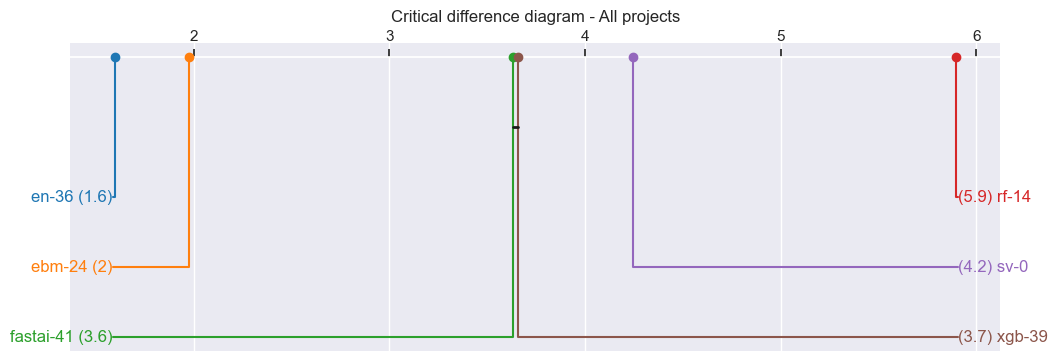

Models not significantly different from the best: ['en-36']


In [17]:
global_comparison = model_comparison(models, label="All projects")

## Accuracy vs computational time

This section complements the statistical comparison based on `RelMSE`. It compares predictive performance against the computational time required to fit and test each model. Lower values are better in both dimensions.

The `tradeoff_rank_80_20` score prioritizes error over time, while `tradeoff_rank_50_50` gives both criteria the same weight. The Pareto frontier marks models that are not dominated by another model with both lower error and lower time.

In [18]:
global_tradeoff_summary = summarize_accuracy_time(models, model_times)
global_tradeoff_summary

,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.012385,0.001655,651.941667,61.0,1.594444,3.829167,2.041389,2.041389,2.711806,215,0,True
1,ebm-24,0.013464,0.001389,1089.672222,724.0,1.975000,5.708333,2.721667,2.721667,3.841667,78,0,True
2,xgb-39,0.027138,0.016280,2.813889,3.0,3.655556,1.025000,3.129444,3.129444,2.340278,0,360,True
3,fastai-41,0.073460,0.021127,74.833333,72.5,3.630556,3.516667,3.607778,3.607778,3.573611,65,0,False
4,sv-0,0.030844,0.023940,16.358333,15.0,4.247222,2.234722,3.844722,3.844722,3.240972,2,0,False
5,rf-14,0.179460,0.178584,277.997222,256.0,5.897222,4.686111,5.655000,5.655000,5.291667,0,0,False


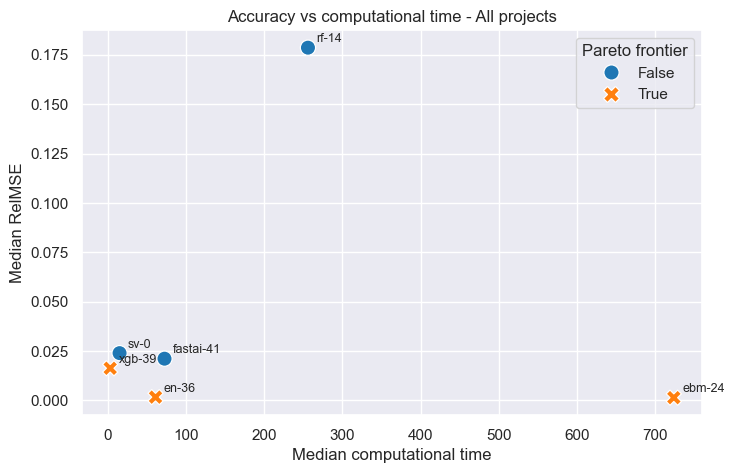

In [19]:
plot_accuracy_time(global_tradeoff_summary, label="All projects")

## Comparison by project subset

Subset J120


,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,en-36,1.400000,1.0,0.536321,0.014533,0.003629,0.024313,56
1,ebm-24,2.122222,2.0,0.632949,0.019142,0.004108,0.034756,12
2,fastai-41,3.422222,3.0,1.655619,0.050575,0.024021,0.094758,22
3,xgb-39,4.011111,4.0,0.786036,0.038752,0.021863,0.040202,0
4,sv-0,4.066667,4.0,0.667041,0.037943,0.019670,0.038014,0
5,rf-14,5.977778,6.0,0.148231,0.254773,0.240990,0.060315,0


Subset J120: 90 projects x 6 models
Friedman's test statistic: 335.213
Friedman's test p-value: 2.66789e-70
Best model by average rank: en-36
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs (bonferroni correction).


model_label,en-36,ebm-24,fastai-41,xgb-39,sv-0,rf-14
model_label,,,,,,
en-36,1.000000e+00,7.595695e-06,3.663489e-37,1.278409e-55,2.083203e-57,1.221906e-117
ebm-24,7.595695e-06,1.000000e+00,2.487845e-17,3.428448e-33,7.822338e-35,1.368048e-95
fastai-41,3.663489e-37,2.487845e-17,1.000000e+00,5.789831e-04,1.040373e-04,7.757700e-54
xgb-39,1.278409e-55,3.428448e-33,5.789831e-04,1.000000e+00,1.000000e+00,1.703482e-35
sv-0,2.083203e-57,7.822338e-35,1.040373e-04,1.000000e+00,1.000000e+00,7.598357e-34
rf-14,1.221906e-117,1.368048e-95,7.757700e-54,1.703482e-35,7.598357e-34,1.000000e+00


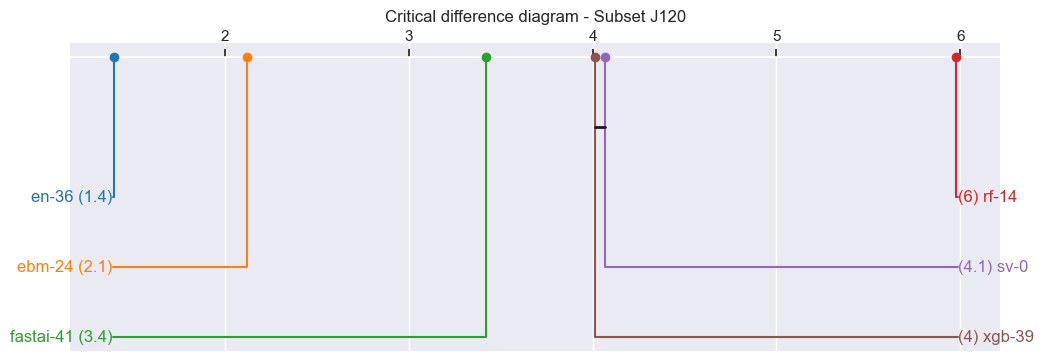

Models not significantly different from the best: ['en-36']
Accuracy-time trade-off for subset J120


,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.014533,0.003629,1480.455556,471.5,1.400000,4.644444,2.048889,2.048889,3.022222,56,0,True
1,ebm-24,0.019142,0.004108,1933.733333,1586.5,2.122222,5.555556,2.808889,2.808889,3.838889,12,0,False
2,fastai-41,0.050575,0.024021,84.944444,83.5,3.422222,3.266667,3.391111,3.391111,3.344444,22,0,False
3,xgb-39,0.038752,0.021863,4.744444,5.0,4.011111,1.000000,3.408889,3.408889,2.505556,0,90,True
4,sv-0,0.037943,0.019670,21.733333,22.0,4.066667,2.033333,3.660000,3.660000,3.050000,0,0,True
5,rf-14,0.254773,0.240990,451.200000,473.5,5.977778,4.500000,5.682222,5.682222,5.238889,0,0,False


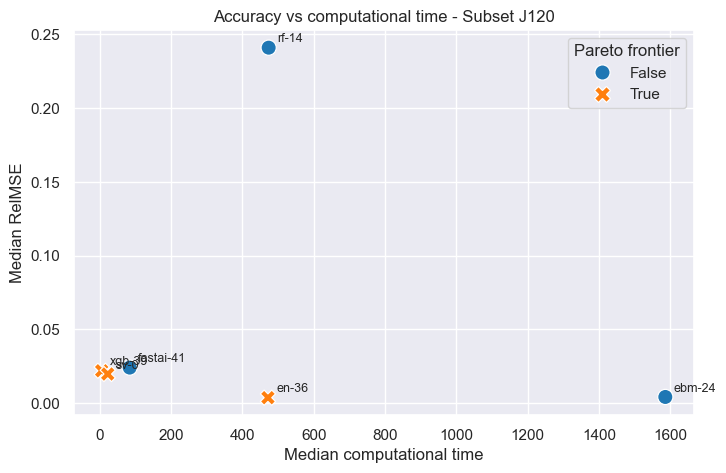

Subset J90


,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,en-36,1.477778,1.0,0.603878,0.014785,0.005664,0.020508,52
1,ebm-24,1.988889,2.0,0.678638,0.016218,0.005821,0.025525,19
2,fastai-41,3.366667,3.0,1.582559,0.073553,0.022610,0.163286,19
3,xgb-39,3.855556,4.0,0.727642,0.034693,0.020973,0.031251,0
4,sv-0,4.366667,4.0,0.626207,0.036160,0.026194,0.023163,0
5,rf-14,5.944444,6.0,0.230345,0.224066,0.217986,0.050244,0


Subset J90: 90 projects x 6 models
Friedman's test statistic: 340.546
Friedman's test p-value: 1.89789e-71
Best model by average rank: en-36
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs (bonferroni correction).


model_label,en-36,ebm-24,fastai-41,xgb-39,sv-0,rf-14
model_label,,,,,,
en-36,1.000000e+00,3.704629e-03,1.558611e-34,5.460693e-50,7.602166e-67,1.560312e-117
ebm-24,3.704629e-03,1.000000e+00,4.654820e-20,7.347992e-34,5.460693e-50,1.134206e-101
fastai-41,1.558611e-34,4.654820e-20,1.000000e+00,6.766084e-03,3.182016e-11,1.523468e-56
xgb-39,5.460693e-50,7.347992e-34,6.766084e-03,1.000000e+00,3.704629e-03,1.001708e-40
sv-0,7.602166e-67,5.460693e-50,3.182016e-11,3.704629e-03,1.000000e+00,1.931308e-25
rf-14,1.560312e-117,1.134206e-101,1.523468e-56,1.001708e-40,1.931308e-25,1.000000e+00


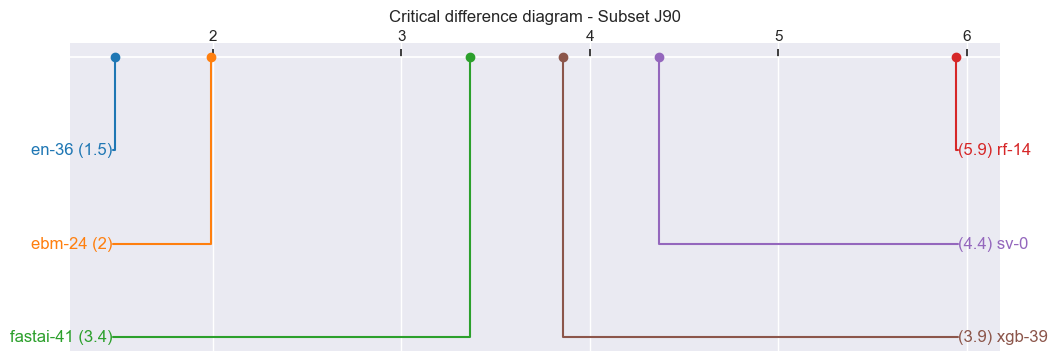

Models not significantly different from the best: ['en-36']
Accuracy-time trade-off for subset J90


,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.014785,0.005664,890.900000,413.0,1.477778,4.566667,2.095556,2.095556,3.022222,52,0,True
1,ebm-24,0.016218,0.005821,1333.333333,1009.5,1.988889,5.533333,2.697778,2.697778,3.761111,19,0,False
2,xgb-39,0.034693,0.020973,3.433333,3.0,3.855556,1.000000,3.284444,3.284444,2.427778,0,90,True
3,fastai-41,0.073553,0.022610,77.488889,78.5,3.366667,3.400000,3.373333,3.373333,3.383333,19,0,False
4,sv-0,0.036160,0.026194,17.577778,17.0,4.366667,2.033333,3.900000,3.900000,3.200000,0,0,False
5,rf-14,0.224066,0.217986,329.277778,342.5,5.944444,4.466667,5.648889,5.648889,5.205556,0,0,False


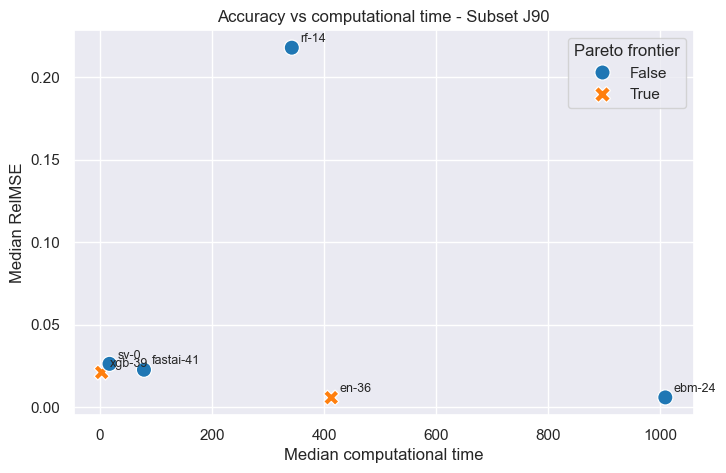

Subset J60


,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,en-36,1.466667,1.0,0.639522,0.010772,0.001162,0.017747,55
1,ebm-24,1.866667,2.0,0.690221,0.011533,0.000880,0.023132,25
2,xgb-39,3.555556,3.5,0.637959,0.023250,0.013655,0.024759,0
3,fastai-41,3.755556,4.0,1.448060,0.069350,0.022471,0.151602,10
4,sv-0,4.455556,5.0,0.721439,0.032922,0.026581,0.014045,0
5,rf-14,5.900000,6.0,0.301681,0.160769,0.156789,0.040814,0


Subset J60: 90 projects x 6 models
Friedman's test statistic: 348.267
Friedman's test p-value: 4.13311e-73
Best model by average rank: en-36
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs (bonferroni correction).


model_label,en-36,ebm-24,xgb-39,fastai-41,sv-0,rf-14
model_label,,,,,,
en-36,1.000000e+00,4.280938e-02,3.442442e-43,7.164370e-50,7.423418e-74,1.643694e-121
ebm-24,4.280938e-02,1.000000e+00,1.962108e-30,1.096377e-36,4.269310e-60,7.845696e-109
xgb-39,3.442442e-43,1.962108e-30,1.000000e+00,1.000000e+00,6.965547e-10,9.462946e-52
fastai-41,7.164370e-50,1.096377e-36,1.000000e+00,1.000000e+00,3.549843e-06,4.965165e-45
sv-0,7.423418e-74,4.269310e-60,6.965547e-10,3.549843e-06,1.000000e+00,2.990567e-23
rf-14,1.643694e-121,7.845696e-109,9.462946e-52,4.965165e-45,2.990567e-23,1.000000e+00


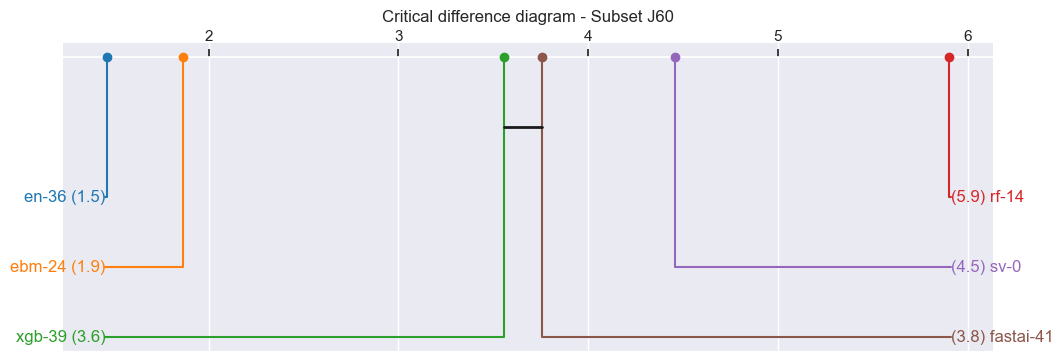

Models not significantly different from the best: ['en-36']
Accuracy-time trade-off for subset J60


,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.010772,0.001162,210.500000,36.5,1.466667,3.650000,1.903333,1.903333,2.558333,55,0,True
1,ebm-24,0.011533,0.000880,741.055556,613.5,1.866667,5.788889,2.651111,2.651111,3.827778,25,0,True
2,xgb-39,0.023250,0.013655,2.077778,2.0,3.555556,1.000000,3.044444,3.044444,2.277778,0,90,True
3,fastai-41,0.069350,0.022471,70.488889,68.0,3.755556,3.533333,3.711111,3.711111,3.644444,10,0,False
4,sv-0,0.032922,0.026581,14.888889,15.0,4.455556,2.250000,4.014444,4.014444,3.352778,0,0,False
5,rf-14,0.160769,0.156789,223.422222,231.0,5.900000,4.777778,5.675556,5.675556,5.338889,0,0,False


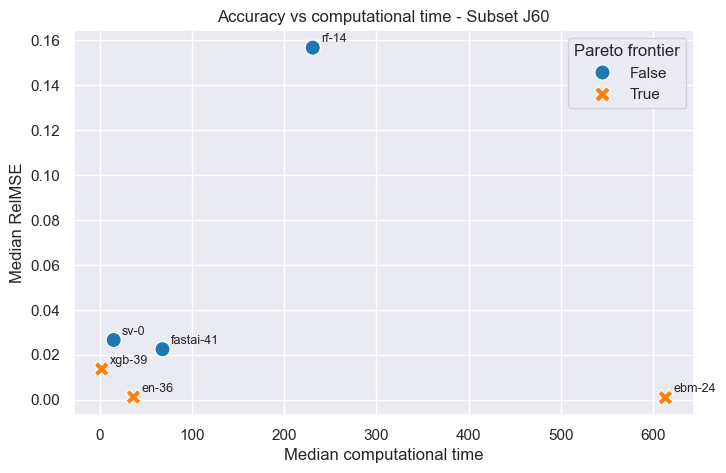

Subset J30


,model,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,std_RelMSE,wins
0,ebm-24,1.922222,2.0,0.737865,0.006962,0.000258,0.014947,22
1,en-36,2.033333,1.0,1.433547,0.009449,0.000459,0.016661,52
2,xgb-39,3.200000,3.0,0.673745,0.011857,0.007216,0.012426,0
3,fastai-41,3.977778,4.5,1.728660,0.100361,0.014297,0.273649,14
4,sv-0,4.100000,4.0,0.948683,0.016352,0.014064,0.007076,2
5,rf-14,5.766667,6.0,0.425322,0.078234,0.078820,0.027630,0


Subset J30: 90 projects x 6 models
Friedman's test statistic: 268.883
Friedman's test p-value: 4.86292e-56
Best model by average rank: ebm-24
Reject null hypothesis that all models perform equally.
Conover post-hoc test for all model pairs (bonferroni correction).


model_label,ebm-24,en-36,xgb-39,fastai-41,sv-0,rf-14
model_label,,,,,,
ebm-24,1.000000e+00,1.000000e+00,4.369907e-11,5.254248e-26,1.021895e-28,3.726712e-70
en-36,1.000000e+00,1.000000e+00,2.284853e-09,1.297568e-23,3.001616e-26,2.741540e-67
xgb-39,4.369907e-11,2.284853e-09,1.000000e+00,2.306943e-04,9.289755e-06,8.438114e-38
fastai-41,5.254248e-26,1.297568e-23,2.306943e-04,1.000000e+00,1.000000e+00,2.159777e-20
sv-0,1.021895e-28,3.001616e-26,9.289755e-06,1.000000e+00,1.000000e+00,5.614172e-18
rf-14,3.726712e-70,2.741540e-67,8.438114e-38,2.159777e-20,5.614172e-18,1.000000e+00


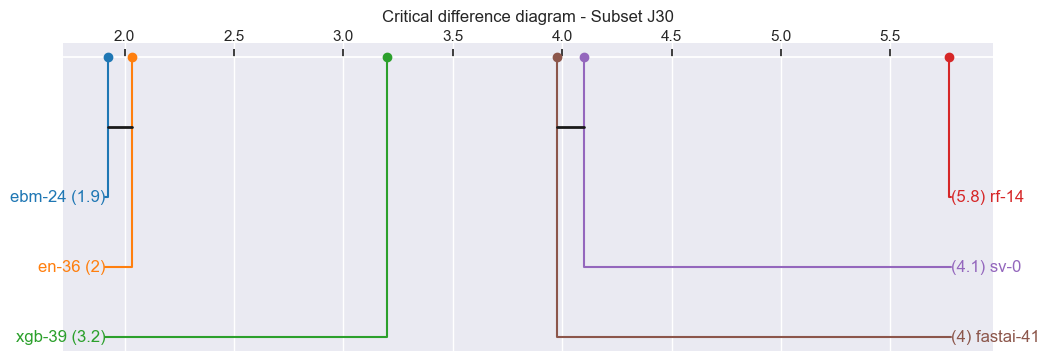

Models not significantly different from the best: ['ebm-24', 'en-36']
Accuracy-time trade-off for subset J30


,model,mean_RelMSE,median_RelMSE,mean_time,median_time,mean_RelMSE_rank,mean_time_rank,tradeoff_rank,tradeoff_rank_80_20,tradeoff_rank_50_50,error_wins,time_wins,pareto_frontier
0,en-36,0.009449,0.000459,25.911111,5.0,2.033333,2.455556,2.117778,2.117778,2.244444,52,0,True
1,ebm-24,0.006962,0.000258,350.566667,282.5,1.922222,5.955556,2.728889,2.728889,3.938889,22,0,True
2,xgb-39,0.011857,0.007216,1.000000,1.0,3.200000,1.100000,2.780000,2.780000,2.150000,0,90,True
3,sv-0,0.016352,0.014064,11.233333,11.0,4.100000,2.622222,3.804444,3.804444,3.361111,2,0,False
4,fastai-41,0.100361,0.014297,66.411111,64.0,3.977778,3.866667,3.955556,3.955556,3.922222,14,0,False
5,rf-14,0.078234,0.078820,108.088889,107.5,5.766667,5.000000,5.613333,5.613333,5.383333,0,0,False


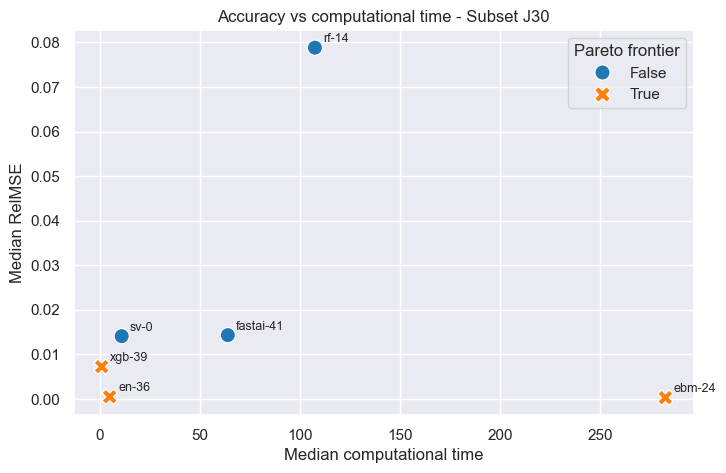

In [20]:
subset_summaries = {}
subset_comparisons = {}
subset_tradeoff_summaries = {}

for subset in subset_order:
    subset_projects = project_subsets.index[project_subsets["subset"].eq(subset)]
    subset_data = models.loc[subset_projects]
    subset_time_data = model_times.loc[subset_projects]

    print("=" * 80)
    print(f"Subset {subset}")
    display(summarize_model_performance(subset_data))

    subset_summaries[subset] = summarize_model_performance(subset_data)
    subset_comparisons[subset] = model_comparison(
        subset_data,
        label=f"Subset {subset}",
        figsize=(12, 4),
    )

    print(f"Accuracy-time trade-off for subset {subset}")
    subset_tradeoff_summaries[subset] = summarize_accuracy_time(subset_data, subset_time_data)
    display(subset_tradeoff_summaries[subset])
    plot_accuracy_time(subset_tradeoff_summaries[subset], label=f"Subset {subset}")

## Consolidated Friedman results

In [22]:
friedman_results = pd.DataFrame([
    {
        "scope": "All",
        "n_projects": global_comparison["n_projects"],
        "best_model": global_comparison["best_model"],
        "friedman_statistic": global_comparison["friedman_statistic"],
        "friedman_pvalue": global_comparison["friedman_pvalue"],
        "best_group": ", ".join(global_comparison["best_group"]),
    },
    *[
        {
            "scope": subset,
            "n_projects": comparison["n_projects"],
            "best_model": comparison["best_model"],
            "friedman_statistic": comparison["friedman_statistic"],
            "friedman_pvalue": comparison["friedman_pvalue"],
            "best_group": ", ".join(comparison["best_group"]),
        }
        for subset, comparison in subset_comparisons.items()
    ],
])

friedman_results

,scope,n_projects,best_model,friedman_statistic,friedman_pvalue,best_group
0,All,360,en-36,1265.453968,1.947062e-271,en-36
1,J120,90,en-36,335.212698,2.667889e-70,en-36
2,J90,90,en-36,340.546032,1.897892e-71,en-36
3,J60,90,en-36,348.266667,4.133106e-73,en-36
4,J30,90,ebm-24,268.882540,4.862925e-56,"ebm-24, en-36"


## Save analysis tables

In [23]:
global_summary.to_csv(work_dir / "model_comparison_summary_all.csv", index=False)
global_tradeoff_summary.to_csv(work_dir / "accuracy_time_tradeoff_all.csv", index=False)
friedman_results.to_csv(work_dir / "friedman_results_all_and_subsets.csv", index=False)

for subset, summary in subset_summaries.items():
    summary.to_csv(work_dir / f"model_comparison_summary_{subset.lower()}.csv", index=False)

for subset, summary in subset_tradeoff_summaries.items():
    summary.to_csv(work_dir / f"accuracy_time_tradeoff_{subset.lower()}.csv", index=False)

if global_comparison["conover_test"] is not None:
    global_comparison["conover_test"].to_csv(work_dir / "conover_all.csv")

for subset, comparison in subset_comparisons.items():
    if comparison["conover_test"] is not None:
        comparison["conover_test"].to_csv(work_dir / f"conover_{subset.lower()}.csv")

## Bootstrap uncertainty over project-level results

The following cells quantify uncertainty and practical effect sizes without retraining any model. The bootstrap unit is the project: each replicate samples projects with replacement and preserves the paired `RelMSE` values of all models for each sampled project.

In [25]:
from itertools import combinations

BOOTSTRAP_SEED = 112358
N_BOOTSTRAP = 10_000
CI_LEVEL = 0.95


def percentile_ci(values, ci_level=CI_LEVEL):
    """Percentile confidence interval."""
    alpha = 1 - ci_level
    return np.quantile(values, [alpha / 2, 1 - alpha / 2])

def paired_dominance(a, b):
    """Dominance effect size for paired losses. Positive values favor a."""
    delta = np.asarray(a) - np.asarray(b)
    wins = np.sum(delta < 0)
    losses = np.sum(delta > 0)
    denom = wins + losses
    return np.nan if denom == 0 else (wins - losses) / denom

def bootstrap_model_summary(
    data,
    n_bootstrap=N_BOOTSTRAP,
    seed=BOOTSTRAP_SEED,
    ci_level=CI_LEVEL,
):
    """Bootstrap model-level mean, median, and rank summaries over projects."""

    clean = data.dropna()
    values = clean.to_numpy()
    models = clean.columns

    rng = np.random.default_rng(seed)
    n_projects = len(clean)
    sample_idx = rng.integers(0, n_projects, size=(n_bootstrap, n_projects))

    ranks = clean.rank(axis=1, ascending=True, method="average")
    rank_values = ranks.to_numpy()

    rows = []
    for j, model in enumerate(models):
        sampled = values[sample_idx, j]
        sampled_ranks = rank_values[sample_idx, j]

        mean_ci = percentile_ci(sampled.mean(axis=1), ci_level)
        median_ci = percentile_ci(np.median(sampled, axis=1), ci_level)
        rank_ci = percentile_ci(sampled_ranks.mean(axis=1), ci_level)

        rows.append({
            "model": model,
            "n_projects": n_projects,
            "mean_RelMSE": clean[model].mean(),
            "mean_RelMSE_ci_low": mean_ci[0],
            "mean_RelMSE_ci_high": mean_ci[1],
            "median_RelMSE": clean[model].median(),
            "median_RelMSE_ci_low": median_ci[0],
            "median_RelMSE_ci_high": median_ci[1],
            "mean_rank": ranks[model].mean(),
            "mean_rank_ci_low": rank_ci[0],
            "mean_rank_ci_high": rank_ci[1],
        })

    return (
        pd.DataFrame(rows)
        .sort_values(["mean_rank", "mean_RelMSE"])
        .reset_index(drop=True)
    )

def bootstrap_pairwise_effects(
    data,
    n_bootstrap=N_BOOTSTRAP,
    seed=BOOTSTRAP_SEED,
    ci_level=CI_LEVEL,
):
    """Bootstrap paired differences, win rates, and dominance effects."""

    clean = data.dropna()
    rng = np.random.default_rng(seed)

    n_projects = len(clean)
    sample_idx = rng.integers(0, n_projects, size=(n_bootstrap, n_projects))

    rows = []
    for model_a, model_b in combinations(clean.columns, 2):
        a = clean[model_a].to_numpy()
        b = clean[model_b].to_numpy()
        delta = a - b

        sampled_delta = delta[sample_idx]

        boot_mean_delta = sampled_delta.mean(axis=1)
        boot_median_delta = np.median(sampled_delta, axis=1)
        boot_win_rate_a = (sampled_delta < 0).mean(axis=1)

        boot_wins = np.sum(sampled_delta < 0, axis=1)
        boot_losses = np.sum(sampled_delta > 0, axis=1)
        boot_dominance_a = (boot_wins - boot_losses) / (boot_wins + boot_losses)

        mean_ci = percentile_ci(boot_mean_delta, ci_level)
        median_ci = percentile_ci(boot_median_delta, ci_level)
        win_ci = percentile_ci(boot_win_rate_a, ci_level)
        dominance_ci = percentile_ci(boot_dominance_a, ci_level)

        rows.append({
            "model_a": model_a,
            "model_b": model_b,
            "n_projects": n_projects,
            "mean_delta_RelMSE_a_minus_b": delta.mean(),
            "mean_delta_ci_low": mean_ci[0],
            "mean_delta_ci_high": mean_ci[1],
            "median_delta_RelMSE_a_minus_b": np.median(delta),
            "median_delta_ci_low": median_ci[0],
            "median_delta_ci_high": median_ci[1],
            "win_rate_a": np.mean(delta < 0),
            "win_rate_a_ci_low": win_ci[0],
            "win_rate_a_ci_high": win_ci[1],
            "tie_rate": np.mean(delta == 0),
            "paired_dominance_a": paired_dominance(a, b),
            "paired_dominance_a_ci_low": dominance_ci[0],
            "paired_dominance_a_ci_high": dominance_ci[1],
        })

    return pd.DataFrame(rows)

def win_rate_matrix(data):
    """Matrix [i, j]: share of projects where model i beats model j."""

    clean = data.dropna()
    values = clean.to_numpy()
    models = clean.columns

    matrix = (values[:, :, None] < values[:, None, :]).mean(axis=0)
    matrix = pd.DataFrame(matrix, index=models, columns=models)
    np.fill_diagonal(matrix.values, np.nan)

    return matrix

## Model-level confidence intervals

This table reports 95% bootstrap confidence intervals for mean `RelMSE`, median `RelMSE`, and mean rank. Lower values are better. These intervals describe uncertainty across project instances, not uncertainty from repeated model training.

In [26]:
bootstrap_model_ci = {"All": bootstrap_model_summary(models)}
bootstrap_model_ci["All"]

,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,en-36,360,0.012385,0.010380,0.014499,0.001655,0.000689,0.003838,1.594444,1.502778,1.691667
1,ebm-24,360,0.013464,0.010903,0.016224,0.001389,0.000637,0.002347,1.975000,1.905556,2.047222
2,fastai-41,360,0.073460,0.056239,0.093919,0.021127,0.017094,0.024651,3.630556,3.461111,3.794444
3,xgb-39,360,0.027138,0.024100,0.030397,0.016280,0.015038,0.017258,3.655556,3.577778,3.736111
4,sv-0,360,0.030844,0.028391,0.033559,0.023940,0.021968,0.025012,4.247222,4.166667,4.325000
5,rf-14,360,0.179460,0.171099,0.188011,0.178584,0.168586,0.193094,5.897222,5.863889,5.927778


In [27]:
subset_bootstrap_model_ci = {}

for subset in subset_order:
    subset_projects = project_subsets.index[project_subsets["subset"].eq(subset)]
    subset_bootstrap_model_ci[subset] = bootstrap_model_summary(
        models.loc[subset_projects],
        seed=BOOTSTRAP_SEED + int(subset.removeprefix("J")),
    )
    print(f"Subset {subset}")
    display(subset_bootstrap_model_ci[subset])


Subset J120


,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,en-36,90,0.014533,0.009899,0.019882,0.003629,0.000787,0.007596,1.400000,1.288889,1.511111
1,ebm-24,90,0.019142,0.012451,0.026745,0.004108,0.000865,0.008571,2.122222,1.988889,2.255556
2,fastai-41,90,0.050575,0.034218,0.072414,0.024021,0.017069,0.033625,3.422222,3.077778,3.755556
3,xgb-39,90,0.038752,0.030927,0.047555,0.021863,0.018791,0.025625,4.011111,3.844444,4.166667
4,sv-0,90,0.037943,0.030685,0.046241,0.019670,0.018056,0.025471,4.066667,3.933333,4.200000
5,rf-14,90,0.254773,0.242674,0.267308,0.240990,0.231464,0.249289,5.977778,5.944444,6.000000


Subset J90


,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,en-36,90,0.014785,0.010814,0.019247,0.005664,0.000576,0.012342,1.477778,1.355556,1.600000
1,ebm-24,90,0.016218,0.011308,0.021762,0.005821,0.000722,0.010996,1.988889,1.855556,2.133333
2,fastai-41,90,0.073553,0.043507,0.110750,0.022610,0.014701,0.029794,3.366667,3.044444,3.688889
3,xgb-39,90,0.034693,0.028645,0.041337,0.020973,0.017007,0.027518,3.855556,3.711111,4.000000
4,sv-0,90,0.036160,0.031703,0.041160,0.026194,0.021995,0.032263,4.366667,4.233333,4.500000
5,rf-14,90,0.224066,0.214011,0.234391,0.217986,0.208135,0.231918,5.944444,5.888889,5.988889


Subset J60


,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,en-36,90,0.010772,0.007315,0.014542,0.001162,0.000245,0.005250,1.466667,1.333333,1.600000
1,ebm-24,90,0.011533,0.007120,0.016533,0.000880,0.000336,0.003003,1.866667,1.733333,2.011111
2,xgb-39,90,0.023250,0.018506,0.028594,0.013655,0.012744,0.014725,3.555556,3.422222,3.688889
3,fastai-41,90,0.069350,0.043080,0.105522,0.022471,0.015066,0.033010,3.755556,3.455556,4.055556
4,sv-0,90,0.032922,0.030180,0.035881,0.026581,0.025797,0.028653,4.455556,4.311111,4.600000
5,rf-14,90,0.160769,0.152808,0.169401,0.156789,0.151940,0.167260,5.900000,5.833333,5.955556


Subset J30


,model,n_projects,mean_RelMSE,mean_RelMSE_ci_low,mean_RelMSE_ci_high,median_RelMSE,median_RelMSE_ci_low,median_RelMSE_ci_high,mean_rank,mean_rank_ci_low,mean_rank_ci_high
0,ebm-24,90,0.006962,0.004196,0.010262,0.000258,0.000057,0.001188,1.922222,1.777778,2.077778
1,en-36,90,0.009449,0.006256,0.012999,0.000459,0.000006,0.001710,2.033333,1.744444,2.333333
2,xgb-39,90,0.011857,0.009562,0.014560,0.007216,0.006571,0.007923,3.200000,3.055556,3.333333
3,fastai-41,90,0.100361,0.053522,0.164423,0.014297,0.011372,0.023340,3.977778,3.622222,4.322222
4,sv-0,90,0.016352,0.014996,0.017859,0.014064,0.013322,0.015107,4.100000,3.900000,4.288889
5,rf-14,90,0.078234,0.072717,0.084014,0.078820,0.070394,0.082788,5.766667,5.677778,5.855556


## Pairwise paired effect sizes

For each pair, `mean_delta_RelMSE_a_minus_b` is `model_a - model_b`. Negative values favor `model_a` because lower `RelMSE` is better. `paired_dominance_a` ranges from -1 to 1 and is positive when `model_a` beats `model_b` on more projects than it loses.

In [28]:
pairwise_effects = {"All": bootstrap_pairwise_effects(models)}
pairwise_effects["All"].sort_values("paired_dominance_a", ascending=False)

,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,360,-0.165997,-0.173365,-0.158662,-0.169983,-0.180750,-0.158374,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,360,-0.013675,-0.014615,-0.012782,-0.012759,-0.013337,-0.011893,0.980556,0.966667,0.994444,0.0,0.961111,0.933333,0.988889
2,ebm-24,sv-0,360,-0.017381,-0.018327,-0.016389,-0.018015,-0.019107,-0.016956,0.955556,0.933333,0.975000,0.0,0.911111,0.866667,0.950000
4,ebm-24,fastai-41,360,-0.059996,-0.080754,-0.042432,-0.011432,-0.014758,-0.009078,0.811111,0.769444,0.850000,0.0,0.622222,0.538889,0.700000
14,en-36,fastai-41,360,-0.061075,-0.081653,-0.043723,-0.011227,-0.014520,-0.008942,0.791667,0.750000,0.833333,0.0,0.583333,0.500000,0.666667
9,xgb-39,sv-0,360,-0.003706,-0.004663,-0.002711,-0.005343,-0.006067,-0.004059,0.766667,0.722222,0.808333,0.0,0.533333,0.444444,0.616667
11,xgb-39,fastai-41,360,-0.046322,-0.067184,-0.028635,-0.000132,-0.004806,0.002450,0.500000,0.447222,0.550000,0.0,0.000000,-0.105556,0.100000
13,sv-0,fastai-41,360,-0.042616,-0.063325,-0.025030,0.005805,0.001332,0.008216,0.427778,0.375000,0.477778,0.0,-0.144444,-0.250000,-0.044444
3,ebm-24,en-36,360,0.001079,0.000155,0.002095,0.000088,0.000064,0.000112,0.277778,0.233333,0.325000,0.0,-0.444444,-0.533333,-0.350000
8,rf-14,fastai-41,360,0.106000,0.083005,0.126041,0.145623,0.130917,0.154589,0.100000,0.069444,0.130556,0.0,-0.800000,-0.861111,-0.738889


In [29]:
subset_pairwise_effects = {}

for subset in subset_order:
    subset_projects = project_subsets.index[project_subsets["subset"].eq(subset)]
    subset_pairwise_effects[subset] = bootstrap_pairwise_effects(
        models.loc[subset_projects],
        seed=BOOTSTRAP_SEED + 1000 + int(subset.removeprefix("J")),
    )
    print(f"Subset {subset}")
    display(subset_pairwise_effects[subset].sort_values("paired_dominance_a", ascending=False))


Subset J120


,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,90,-0.235631,-0.244245,-0.226829,-0.233633,-0.243719,-0.229784,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,90,-0.019610,-0.021363,-0.017982,-0.017241,-0.018458,-0.016393,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
2,ebm-24,sv-0,90,-0.018801,-0.020392,-0.017275,-0.016477,-0.017198,-0.016056,0.988889,0.966667,1.000000,0.0,0.977778,0.933333,1.000000
4,ebm-24,fastai-41,90,-0.031433,-0.054154,-0.013253,-0.010961,-0.021771,-0.007340,0.744444,0.655556,0.833333,0.0,0.488889,0.311111,0.666667
14,en-36,fastai-41,90,-0.036042,-0.057961,-0.018837,-0.011225,-0.021983,-0.007867,0.744444,0.655556,0.833333,0.0,0.488889,0.311111,0.666667
9,xgb-39,sv-0,90,0.000809,-0.000511,0.002182,-0.000122,-0.001218,0.000831,0.522222,0.422222,0.622222,0.0,0.044444,-0.155556,0.244444
11,xgb-39,fastai-41,90,-0.011823,-0.035127,0.007077,0.004310,-0.005272,0.009001,0.466667,0.366667,0.566667,0.0,-0.066667,-0.266667,0.133333
13,sv-0,fastai-41,90,-0.012632,-0.035528,0.005807,0.005805,-0.004920,0.009552,0.444444,0.344444,0.544444,0.0,-0.111111,-0.311111,0.088889
3,ebm-24,en-36,90,0.004609,0.002293,0.007305,0.000225,0.000211,0.000361,0.144444,0.077778,0.222222,0.0,-0.711111,-0.844444,-0.555556
8,rf-14,fastai-41,90,0.204198,0.178787,0.225181,0.211634,0.202451,0.219108,0.022222,0.000000,0.055556,0.0,-0.955556,-1.000000,-0.888889


Subset J90


,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,90,-0.207848,-0.215587,-0.200090,-0.208247,-0.216753,-0.198874,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,90,-0.018476,-0.020378,-0.016766,-0.015941,-0.016949,-0.014813,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
2,ebm-24,sv-0,90,-0.019942,-0.021025,-0.018801,-0.020144,-0.021009,-0.019640,0.977778,0.944444,1.000000,0.0,0.955556,0.888889,1.000000
4,ebm-24,fastai-41,90,-0.057336,-0.095627,-0.026974,-0.009221,-0.014563,-0.006792,0.777778,0.688889,0.855556,0.0,0.555556,0.377778,0.711111
14,en-36,fastai-41,90,-0.058769,-0.096659,-0.028649,-0.009244,-0.014668,-0.005936,0.777778,0.688889,0.855556,0.0,0.555556,0.377778,0.711111
9,xgb-39,sv-0,90,-0.001466,-0.003258,0.000546,-0.004053,-0.005434,-0.003078,0.755556,0.666667,0.844444,0.0,0.511111,0.333333,0.688889
11,xgb-39,fastai-41,90,-0.038860,-0.077378,-0.007948,0.004772,0.001143,0.008872,0.388889,0.288889,0.488889,0.0,-0.222222,-0.422222,-0.022222
13,sv-0,fastai-41,90,-0.037394,-0.075445,-0.006923,0.010789,0.006108,0.014314,0.366667,0.266667,0.466667,0.0,-0.266667,-0.466667,-0.066667
3,ebm-24,en-36,90,0.001433,0.000044,0.003002,0.000123,0.000112,0.000151,0.255556,0.166667,0.344444,0.0,-0.488889,-0.666667,-0.311111
8,rf-14,fastai-41,90,0.150512,0.110762,0.183342,0.190507,0.171021,0.205015,0.055556,0.011111,0.111111,0.0,-0.888889,-0.977778,-0.777778


Subset J60


,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,90,-0.149236,-0.155527,-0.142789,-0.146447,-0.155442,-0.140718,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,90,-0.011717,-0.012438,-0.010997,-0.011464,-0.012020,-0.010374,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
2,ebm-24,sv-0,90,-0.021389,-0.023325,-0.019077,-0.024177,-0.024777,-0.023860,0.944444,0.888889,0.988889,0.0,0.888889,0.777778,0.977778
9,xgb-39,sv-0,90,-0.009672,-0.011865,-0.007136,-0.013190,-0.014031,-0.012211,0.911111,0.844444,0.966667,0.0,0.822222,0.688889,0.933333
4,ebm-24,fastai-41,90,-0.057818,-0.093656,-0.032145,-0.013084,-0.022861,-0.009398,0.877778,0.800000,0.944444,0.0,0.755556,0.600000,0.888889
14,en-36,fastai-41,90,-0.058579,-0.094448,-0.032669,-0.012623,-0.023477,-0.008471,0.855556,0.777778,0.922222,0.0,0.711111,0.555556,0.844444
11,xgb-39,fastai-41,90,-0.046101,-0.082019,-0.020410,-0.001818,-0.011338,0.003207,0.522222,0.422222,0.622222,0.0,0.044444,-0.155556,0.244444
13,sv-0,fastai-41,90,-0.036429,-0.072229,-0.010628,0.009167,0.000522,0.015622,0.400000,0.300000,0.500000,0.0,-0.200000,-0.400000,0.000000
3,ebm-24,en-36,90,0.000761,-0.000893,0.002730,0.000064,0.000057,0.000074,0.311111,0.222222,0.411111,0.0,-0.377778,-0.555556,-0.177778
8,rf-14,fastai-41,90,0.091418,0.055859,0.117009,0.126042,0.112633,0.140423,0.100000,0.044444,0.166667,0.0,-0.800000,-0.911111,-0.666667


Subset J30


,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high
0,ebm-24,rf-14,90,-0.071272,-0.076414,-0.066243,-0.070477,-0.078448,-0.066413,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000
1,ebm-24,xgb-39,90,-0.004895,-0.005639,-0.004058,-0.005473,-0.005892,-0.005072,0.922222,0.866667,0.977778,0.0,0.844444,0.733333,0.955556
2,ebm-24,sv-0,90,-0.009390,-0.011048,-0.007440,-0.011865,-0.012508,-0.011200,0.911111,0.844444,0.966667,0.0,0.822222,0.688889,0.933333
9,xgb-39,sv-0,90,-0.004495,-0.005742,-0.003141,-0.005991,-0.007209,-0.005263,0.877778,0.811111,0.944444,0.0,0.755556,0.622222,0.888889
4,ebm-24,fastai-41,90,-0.093399,-0.158243,-0.046187,-0.012317,-0.020263,-0.007187,0.844444,0.766667,0.911111,0.0,0.688889,0.533333,0.822222
14,en-36,fastai-41,90,-0.090912,-0.156033,-0.043710,-0.012024,-0.019632,-0.006908,0.788889,0.700000,0.866667,0.0,0.577778,0.400000,0.733333
11,xgb-39,fastai-41,90,-0.088503,-0.153100,-0.041214,-0.006325,-0.015824,-0.001758,0.622222,0.522222,0.722222,0.0,0.244444,0.044444,0.444444
13,sv-0,fastai-41,90,-0.084009,-0.148562,-0.036819,-0.000960,-0.008335,0.004380,0.500000,0.400000,0.600000,0.0,0.000000,-0.200000,0.200000
3,ebm-24,en-36,90,-0.002487,-0.003888,-0.001049,0.000027,-0.000010,0.000032,0.400000,0.300000,0.500000,0.0,-0.200000,-0.400000,0.000000
8,rf-14,fastai-41,90,-0.022127,-0.086869,0.026026,0.047847,0.029362,0.060484,0.222222,0.133333,0.311111,0.0,-0.555556,-0.733333,-0.377778


## Pairwise win-rate matrices

Each cell contains the share of projects where the row model has lower `RelMSE` than the column model. This is often the most interpretable effect-size summary for paired benchmark results.

In [30]:
global_win_rate_matrix = win_rate_matrix(models)
global_win_rate_matrix.style.format("{:.3f}").background_gradient(cmap="viridis", axis=None)

model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,0.981,0.956,0.278,0.811
rf-14,0.000,nan,0.000,0.003,0.000,0.100
xgb-39,0.019,1.000,nan,0.767,0.058,0.500
sv-0,0.044,0.997,0.233,nan,0.050,0.428
en-36,0.722,1.000,0.942,0.950,nan,0.792
fastai-41,0.189,0.900,0.500,0.572,0.208,nan


In [31]:
subset_win_rate_matrices = {}

for subset in subset_order:
    subset_projects = project_subsets.index[project_subsets["subset"].eq(subset)]
    subset_win_rate_matrices[subset] = win_rate_matrix(models.loc[subset_projects])
    print(f"Subset {subset}")
    display(subset_win_rate_matrices[subset].style.format("{:.3f}").background_gradient(cmap="viridis", axis=None))


Subset J120


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,1.000,0.989,0.144,0.744
rf-14,0.000,nan,0.000,0.000,0.000,0.022
xgb-39,0.000,1.000,nan,0.522,0.000,0.467
sv-0,0.011,1.000,0.478,nan,0.000,0.444
en-36,0.856,1.000,1.000,1.000,nan,0.744
fastai-41,0.256,0.978,0.533,0.556,0.256,nan


Subset J90


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,1.000,0.978,0.256,0.778
rf-14,0.000,nan,0.000,0.000,0.000,0.056
xgb-39,0.000,1.000,nan,0.756,0.000,0.389
sv-0,0.022,1.000,0.244,nan,0.000,0.367
en-36,0.744,1.000,1.000,1.000,nan,0.778
fastai-41,0.222,0.944,0.611,0.633,0.222,nan


Subset J60


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,1.000,0.944,0.311,0.878
rf-14,0.000,nan,0.000,0.000,0.000,0.100
xgb-39,0.000,1.000,nan,0.911,0.011,0.522
sv-0,0.056,1.000,0.089,nan,0.000,0.400
en-36,0.689,1.000,0.989,1.000,nan,0.856
fastai-41,0.122,0.900,0.478,0.600,0.144,nan


Subset J30


model_label,ebm-24,rf-14,xgb-39,sv-0,en-36,fastai-41
model_label,,,,,,
ebm-24,nan,1.000,0.922,0.911,0.400,0.844
rf-14,0.000,nan,0.000,0.011,0.000,0.222
xgb-39,0.078,1.000,nan,0.878,0.222,0.622
sv-0,0.089,0.989,0.122,nan,0.200,0.500
en-36,0.600,1.000,0.778,0.800,nan,0.789
fastai-41,0.156,0.778,0.378,0.500,0.211,nan


## Practical-equivalence checks

The threshold below should be justified in the paper. It is a reviewer-facing way to distinguish statistically significant differences from differences that are too small to matter operationally.

In [32]:
PRACTICAL_DELTA_RELMSE = 0.001

def add_practical_equivalence_flags(pairwise_df, threshold=PRACTICAL_DELTA_RELMSE):
    """Add practical equivalence flags for pairwise RelMSE differences."""

    pairwise_df = pairwise_df.copy()

    median_delta = pairwise_df["median_delta_RelMSE_a_minus_b"]
    ci_low = pairwise_df["mean_delta_ci_low"]
    ci_high = pairwise_df["mean_delta_ci_high"]

    pairwise_df["practical_equivalence_median"] = median_delta.abs() <= threshold
    pairwise_df["mean_ci_intersects_practical_band"] = (
        (ci_low <= threshold) & (ci_high >= -threshold)
    )
    pairwise_df["practical_delta_threshold"] = threshold

    return pairwise_df


pairwise_effects_practical = {
    scope: add_practical_equivalence_flags(df)
    for scope, df in pairwise_effects.items()
}

subset_pairwise_effects_practical = {
    subset: add_practical_equivalence_flags(df)
    for subset, df in subset_pairwise_effects.items()
}

pairwise_effects_practical["All"].sort_values(
    ["practical_equivalence_median", "mean_delta_RelMSE_a_minus_b"],
    ascending=[False, True],
)

,model_a,model_b,n_projects,mean_delta_RelMSE_a_minus_b,mean_delta_ci_low,mean_delta_ci_high,median_delta_RelMSE_a_minus_b,median_delta_ci_low,median_delta_ci_high,win_rate_a,win_rate_a_ci_low,win_rate_a_ci_high,tie_rate,paired_dominance_a,paired_dominance_a_ci_low,paired_dominance_a_ci_high,practical_equivalence_median,mean_ci_intersects_practical_band,practical_delta_threshold
11,xgb-39,fastai-41,360,-0.046322,-0.067184,-0.028635,-0.000132,-0.004806,0.002450,0.500000,0.447222,0.550000,0.0,0.000000,-0.105556,0.100000,True,False,0.001
3,ebm-24,en-36,360,0.001079,0.000155,0.002095,0.000088,0.000064,0.000112,0.277778,0.233333,0.325000,0.0,-0.444444,-0.533333,-0.350000,True,True,0.001
0,ebm-24,rf-14,360,-0.165997,-0.173365,-0.158662,-0.169983,-0.180750,-0.158374,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,False,False,0.001
14,en-36,fastai-41,360,-0.061075,-0.081653,-0.043723,-0.011227,-0.014520,-0.008942,0.791667,0.750000,0.833333,0.0,0.583333,0.500000,0.666667,False,False,0.001
4,ebm-24,fastai-41,360,-0.059996,-0.080754,-0.042432,-0.011432,-0.014758,-0.009078,0.811111,0.769444,0.850000,0.0,0.622222,0.538889,0.700000,False,False,0.001
13,sv-0,fastai-41,360,-0.042616,-0.063325,-0.025030,0.005805,0.001332,0.008216,0.427778,0.375000,0.477778,0.0,-0.144444,-0.250000,-0.044444,False,False,0.001
2,ebm-24,sv-0,360,-0.017381,-0.018327,-0.016389,-0.018015,-0.019107,-0.016956,0.955556,0.933333,0.975000,0.0,0.911111,0.866667,0.950000,False,False,0.001
1,ebm-24,xgb-39,360,-0.013675,-0.014615,-0.012782,-0.012759,-0.013337,-0.011893,0.980556,0.966667,0.994444,0.0,0.961111,0.933333,0.988889,False,False,0.001
9,xgb-39,sv-0,360,-0.003706,-0.004663,-0.002711,-0.005343,-0.006067,-0.004059,0.766667,0.722222,0.808333,0.0,0.533333,0.444444,0.616667,False,False,0.001
10,xgb-39,en-36,360,0.014753,0.013249,0.016343,0.012676,0.011639,0.013504,0.058333,0.036111,0.083333,0.0,-0.883333,-0.927778,-0.833333,False,False,0.001


## Save uncertainty and effect-size tables

These CSV files complement the Friedman and Conover p-value tables with confidence intervals, paired differences, dominance effects, and win-rate matrices.

In [33]:
bootstrap_model_ci["All"].to_csv(work_dir / "bootstrap_model_ci_all.csv", index=False)
pairwise_effects_practical["All"].to_csv(work_dir / "pairwise_effect_sizes_all.csv", index=False)
global_win_rate_matrix.to_csv(work_dir / "pairwise_win_rates_all.csv")

for subset, summary in subset_bootstrap_model_ci.items():
    summary.to_csv(work_dir / f"bootstrap_model_ci_{subset.lower()}.csv", index=False)

for subset, effects in subset_pairwise_effects_practical.items():
    effects.to_csv(work_dir / f"pairwise_effect_sizes_{subset.lower()}.csv", index=False)

for subset, matrix in subset_win_rate_matrices.items():
    matrix.to_csv(work_dir / f"pairwise_win_rates_{subset.lower()}.csv")
